<img src = "https://drive.google.com/uc?export=view&id=1lrzkRlmABf8ZwwCzsSvo0b2lW_IhZXkv" alt = "Encabezado MLDS" width = "100%">  </img>


# **Preparación de los datos**
---

Este notebook es una plantilla que le puede servir como guía para el tercer entregable del proyecto aplicado.

## **0. Integrantes del equipo de trabajo**
---

Por favor incluya los nombres completos y número de identificación de los integrantes del equipo de trabajo:

1. ---**Alejandra Jaramillo Mejia 1002652912**---
2. ---**Santiago Chaparro Suzunaga 1002760592**---
3. ---**Brayan Sebastian Yepes Garcia 1015457884**---

In [ ]:
import zipfile
import tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# --- Ubicación de los datos en el repositorio ---
DATA_DIR = Path(
    "../../data/raw/elecciones_2026/extracted/"
    "MMV_Presidente1V_2026/MMV_Presidente1V_2026"
)
assert DATA_DIR.is_dir(), f"No se encontró el directorio de datos: {DATA_DIR.resolve()}"

# Los ZIP internos (catálogos y novedades) se descomprimen en una carpeta temporal,
# para no modificar la carpeta de datos originales del repositorio.
EXTRA_DIR = Path(tempfile.gettempdir()) / "mmv_presidente_2026"
EXTRA_DIR.mkdir(parents=True, exist_ok=True)
for zip_interno in ["ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3.zip", "Novedad20260603.zip"]:
    with zipfile.ZipFile(DATA_DIR / zip_interno) as z:
        z.extractall(EXTRA_DIR / Path(zip_interno).stem)

def buscar_archivo(patron, directorios=(DATA_DIR, EXTRA_DIR)):
    for d in directorios:
        resultados = list(Path(d).rglob(patron))
        if resultados:
            return resultados[0]
    raise FileNotFoundError(f"No se encontró '{patron}'")

ARCH_PRECONTEO  = buscar_archivo("PRE1v_MMV_9999_PRECONTEO.txt")
ARCH_ESCRUTINIO = buscar_archivo("_ficheros_MMV_4_MMV_9999_ESCRUTINIO.csv")
ARCH_NOVEDADES  = buscar_archivo("Novedad20260603.csv")
DIR_BASICOS     = buscar_archivo("HASH.txt").parent
PRECONTEO_PATH  = ARCH_PRECONTEO          # nombre que usa la sección de preconteo

# --- Preconteo (ancho fijo) ---
COLS_PRE   = ["dep", "mun", "zona", "puesto", "mesa", "jal", "comunicado",
              "circ", "partido", "candidato", "votos"]
ANCHOS_PRE = [2, 3, 2, 2, 6, 2, 4, 1, 5, 3, 8]
precon = pd.read_fwf(ARCH_PRECONTEO, widths=ANCHOS_PRE, names=COLS_PRE,
                     dtype=str, encoding="latin-1")
precon["votos"] = precon["votos"].astype("int64")

# --- Escrutinio (separado por ;) ---
COLS_ESC = ["comunicado", "dep", "mun", "zona", "puesto", "mesa", "comuna",
            "corporacion", "circ", "partido", "candidato", "votos"]
escru = pd.read_csv(ARCH_ESCRUTINIO, sep=";", header=None, usecols=range(12),
                    names=COLS_ESC, dtype=str, encoding="latin-1")
escru["votos"] = escru["votos"].astype("int64")

# --- Novedades (UTF-8; repara las 45 líneas con comas en el nombre del puesto) ---
def leer_novedades(ruta):
    with open(ruta, encoding="utf-8") as f:
        encabezado = f.readline().rstrip("\r\n").split(",")
        n_campos, i_nombre = len(encabezado), encabezado.index("puestoNombre")
        n_cola = n_campos - i_nombre - 1
        filas = []
        for linea in f:
            partes = linea.rstrip("\r\n").split(",")
            if len(partes) > n_campos:
                partes = (partes[:i_nombre]
                          + [",".join(partes[i_nombre:len(partes) - n_cola])]
                          + partes[-n_cola:])
            filas.append(partes)
    return pd.DataFrame(filas, columns=encabezado)

noved = leer_novedades(ARCH_NOVEDADES)
COLS_NUM_NOV = ["potencial", "sufragantesSegunE11", "firmasJurados", "votosUrna",
                "votosIncinerados", "sufragantesE11SegunE14", "totalVotos"]
noved[COLS_NUM_NOV] = noved[COLS_NUM_NOV].apply(pd.to_numeric, errors="coerce")

# --- Catálogos (ancho fijo) ---
def leer_catalogo(prefijo, anchos, nombres):
    ruta = next(DIR_BASICOS.glob(f"{prefijo}_*.TXT"))
    df = pd.read_fwf(ruta, widths=anchos, names=nombres, dtype=str, encoding="latin-1")
    return df.apply(lambda s: s.str.strip())

divipol = leer_catalogo(
    "DIVIPOL", [2, 3, 2, 2, 12, 30, 40, 1, 8, 8, 6, 2, 30],
    ["dep", "mun", "zona", "puesto", "dep_nombre", "mun_nombre", "puesto_nombre",
     "indicador_puesto", "potencial_hombres", "potencial_mujeres", "n_mesas",
     "comuna", "comuna_nombre"])
for c in ["potencial_hombres", "potencial_mujeres", "n_mesas"]:
    divipol[c] = divipol[c].astype("int64")
candidatos = leer_catalogo(
    "CANDIDATOS", [3, 1, 2, 3, 2, 5, 3, 1, 50, 50, 15, 1, 2],
    ["corporacion", "circ", "dep", "mun", "comuna", "partido", "candidato",
     "preferente", "nombre", "apellido", "cedula", "genero", "sorteo"])

# --- Normalización de llaves ---
LLAVE_MESA = ["dep", "mun", "zona", "puesto", "mesa"]
for df in (precon, escru):
    df["zona"] = df["zona"].str.zfill(3)
    df["partido"] = df["partido"].str.zfill(5)
divipol["zona"] = divipol["zona"].str.zfill(3)
noved = noved.rename(columns={"departamentoCodigo": "dep", "municipioCodigo": "mun",
                              "zonaNombre": "zona", "puestoCodigo": "puesto",
                              "mesaNumero": "mesa"})
noved["zona"] = noved["zona"].str.zfill(3)
noved["mesa"] = noved["mesa"].str.zfill(6)

print(f"Preconteo: {len(precon):,} | Escrutinio: {len(escru):,} | "
      f"Novedades: {len(noved):,} | DIVIPOL: {len(divipol):,}")

Preconteo: 1,479,506 | Escrutinio: 1,952,320 | Novedades: 118,350 | DIVIPOL: 14,438


## **1. Limpieza de los Datos**
---

La elección de las técnicas de preprocesamiento puede diferir en cada conjunto de datos. Recuerde que es posible aplicar, según sea necesario (no necesariamente todas), las técnicas generales que se han explorado en el curso. La elección dependerá del tipo de datos con el que esté trabajando.

A lo largo de esta entrega, busque responder las siguientes preguntas:

- ¿Cuáles fueron los criterios utilizados para identificar y tratar valores atípicos, datos faltantes o cualquier otra anomalía en el conjunto de datos durante el proceso de limpieza?
- ¿Cómo se justificaría la necesidad de cada paso de preprocesamiento en términos de mejora de la calidad de los datos y preparación para el análisis subsiguiente?

A continuación encontrará los puntos a tratar a medida que va realizando la preparación de los datos. En cada punto defina el estado en que se encontraba el dataset, ademas de explicar y justificar las acciones y decisiones que se tomaron.

### **1.1. Valores faltantes**
---
Al encontrarnos con valores faltantes en el conjunto de datos, es crucial preguntarse:
* ¿Cómo afectan estos valores a la integridad y representatividad de la información?
* ¿Cómo se identificaron los valores faltantes en el conjunto de datos?
* ¿Cuáles fueron los criterios para decidir si rellenar con valores estimados o eliminar los valores faltantes? En caso que aplique, ¿qué método de relleno se utilizó y por qué se consideró apropiado?
* ¿Se realizó un análisis de la distribución de los valores faltantes en relación con las variables clave? Por ejemplo, si hay valores faltantes en una variable crítica, ¿cómo podría afectar la interpretación de los resultados?

#### Escrutinio

**¿Cómo se identificaron los valores faltantes en el conjunto de datos?**

In [ ]:
print("Valores nulos por columna:")
print(escru.isnull().sum())

texto = escru.select_dtypes(exclude="number").columns
print("\nCeldas vacías o solo con espacios:", (escru[texto].apply(lambda s: s.str.strip()) == "").sum().sum())

filas_mesa = escru.groupby(LLAVE_MESA).size()
print("\nMesas:", len(filas_mesa), "| filas por mesa:", filas_mesa.value_counts().to_dict())
print("Filas esperadas (mesas x 16):", len(filas_mesa) * 16, "| filas reales:", len(escru))

Valores nulos por columna:


comunicado     0
dep            0
mun            0
zona           0
puesto         0
mesa           0
comuna         0
corporacion    0
circ           0
partido        0
candidato      0
votos          0
dtype: int64



Celdas vacías o solo con espacios: 0



Mesas: 122020 | filas por mesa: {16: 122020}
Filas esperadas (mesas x 16): 1952320 | filas reales: 1952320


Se revisaron tres formas en que un dato puede faltar:

1. **Valores nulos** (`isnull`): ninguna de las 12 columnas tiene nulos.
2. **Celdas vacías o con solo espacios**, que `isnull` no detecta porque se leen como texto: hay 0.
3. **Filas ausentes**: en un archivo en formato largo, un dato también falta si una mesa no tiene fila para alguna candidatura. Las 122 020 mesas tienen exactamente 16 filas, una por cada opción, y el total de filas (1 952 320) es igual a mesas × 16. El escrutinio trae la rejilla completa.

En conclusión, el estado inicial del escrutinio es **sin valores faltantes**. Esto lo diferencia del preconteo, al que le faltan filas. Cuando se comparen las dos fuentes, el escrutinio sirve de referencia completa.

**¿Se realizó un análisis de la distribución de los valores faltantes en relación con las variables clave?**

candidato
001      0.1
002     41.4
003     34.8
004      0.6
005     73.5
006     81.6
007     86.4
008     90.0
009    100.0
010     96.2
011      4.7
012     10.9
013    100.0
996     12.1
997     29.0
998     65.4


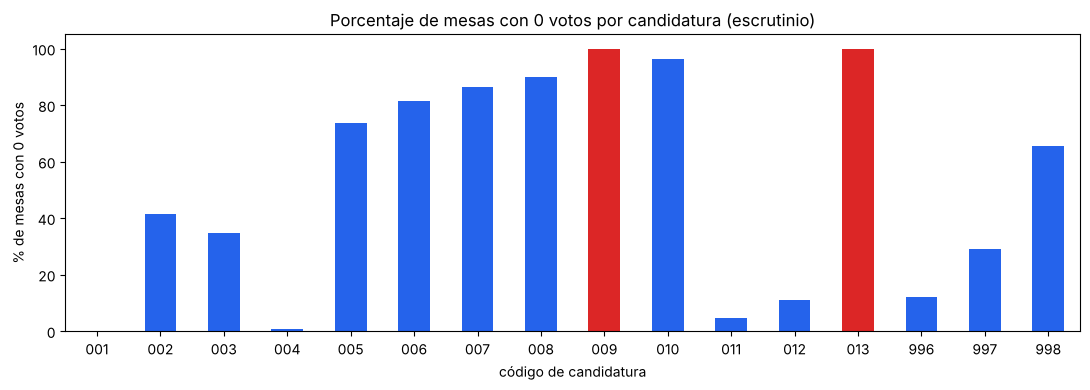

In [ ]:
pct_ceros = escru.groupby("candidato")["votos"].apply(lambda s: (s == 0).mean() * 100).round(1)
print(pct_ceros.to_string())

fig, ax = plt.subplots(figsize=(11, 4))
colores = ["#DC2626" if c in ("009", "013") else "#2563EB" for c in pct_ceros.index]
pct_ceros.plot.bar(ax=ax, color=colores)
ax.set_xlabel("código de candidatura")
ax.set_ylabel("% de mesas con 0 votos")
ax.set_title("Porcentaje de mesas con 0 votos por candidatura (escrutinio)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

*Figura: Porcentaje de mesas con 0 votos por candidatura en el escrutinio; en rojo, los candidatos retirados (elaboración propia).*

Aunque no hay faltantes, se revisó si algún **cero** podía ser en realidad un dato faltante. Un 0 en `votos` es un valor registrado: la candidatura no recibió votos en esa mesa. La proporción de ceros depende de cada candidatura, desde 0,1 % (001) hasta 96,2 % (010), lo que refleja su votación y no una falla de registro.

La excepción son **009 y 013, con 0 votos en el 100 % de las mesas**. No es que falten sus datos: los dos candidatos se retiraron y en el escrutinio sus votos pasaron al código 998. Son columnas sin información, pero no se rellenan ni se reconstruyen. El traslado se descuenta al construir la variable objetivo, y la decisión sobre conservarlas o eliminarlas se toma en la selección de datos (1.6).

In [ ]:
votos_mesa = escru.groupby(LLAVE_MESA)["votos"].sum().reset_index()
mesas_cero = votos_mesa[votos_mesa["votos"] == 0]
mesas_cero = mesas_cero.merge(noved[LLAVE_MESA + ["excluida"]], on=LLAVE_MESA, how="left")
mesas_cero["origen"] = np.where(mesas_cero["dep"] == "88", "consulado",
                       np.where(mesas_cero["excluida"] == "SI", "excluida en escrutinio", "otra"))

print("Mesas con 0 votos en total:", len(mesas_cero))
print(mesas_cero["origen"].value_counts())
print("Mesas excluidas en todo el archivo de novedades:", (noved["excluida"] == "SI").sum())

pre_mesa = precon.groupby(LLAVE_MESA)["votos"].sum().rename("votos_pre").reset_index()
excluidas = mesas_cero[mesas_cero["origen"] == "excluida en escrutinio"].merge(pre_mesa, on=LLAVE_MESA)
print("Excluidas con votos en el preconteo:", (excluidas["votos_pre"] > 0).sum(), "de", len(excluidas))

Mesas con 0 votos en total: 46
origen
excluida en escrutinio    37
consulado                  9
Name: count, dtype: int64
Mesas excluidas en todo el archivo de novedades: 37


Excluidas con votos en el preconteo: 37 de 37


También se revisaron las mesas **sin ningún voto**, porque una mesa vacía podría ser un acta que no llegó. Hay 46 y todas tienen explicación:

- **37 mesas excluidas en el escrutinio.** Son exactamente las 37 que el archivo de novedades marca con `excluida = SI`: la comisión anuló su votación. No son faltantes sino el resultado real del escrutinio, así que **se conservan**. Además, son mesas corregidas (en el preconteo sí tenían votos), por lo que eliminarlas quitaría casos positivos de la variable objetivo.
- **9 mesas de consulados** donde nadie votó.

**¿Cuáles fueron los criterios para decidir si rellenar con valores estimados o eliminar los valores faltantes?**

En el escrutinio no fue necesario rellenar ni eliminar registros, porque no hay valores faltantes. El criterio aplicado fue verificar si los valores que podían parecer faltantes lo eran en realidad:

- **Ceros por candidatura:** son valores reales (nadie votó por esa opción en la mesa) y se conservan tal como están.
- **Ceros de 009 y 013:** se deben al retiro de los candidatos, no a datos perdidos. No se rellenan. El traslado de sus votos se descuenta al construir la variable objetivo, y en la selección de datos (1.6) se decide si sus columnas se conservan.
- **Las 46 mesas sin votos:** corresponden a 37 mesas excluidas por la comisión y 9 mesas de consulados donde nadie votó. Son resultados reales, por lo que se conservan.

**Método de relleno:** no aplica. No se usó ningún método de relleno (media, mediana, moda ni otro), porque en el escrutinio no hay valores faltantes y los ceros son resultados reales. Rellenarlos cambiaría los votos de cada mesa.

#### Faltantes al cruzar el escrutinio con las novedades

El escrutinio está completo por sí solo. Sin embargo, para construir el conjunto de modelado hay que unirlo con el archivo de novedades, que aporta las variables del formulario (E-11, E-14, votos en urna, firmas). Por eso se revisó si alguna mesa del escrutinio queda sin esa información al hacer el cruce.

In [ ]:
votos_mesa = escru.groupby(LLAVE_MESA)["votos"].sum().reset_index()
cruce = votos_mesa[LLAVE_MESA].merge(noved[LLAVE_MESA], on=LLAVE_MESA, how="left", indicator=True)

print("Mesas del escrutinio:", len(cruce))
print("Mesas con registro en novedades:", (cruce["_merge"] == "both").sum())
print("Mesas sin registro en novedades:", (cruce["_merge"] == "left_only").sum())
print("\nDepartamento de las mesas sin novedades:")
print(cruce.loc[cruce["_merge"] == "left_only", "dep"].value_counts())

Mesas del escrutinio: 122020
Mesas con registro en novedades: 118350
Mesas sin registro en novedades: 3670

Departamento de las mesas sin novedades:
dep
88    3670
Name: count, dtype: int64


In [ ]:
votos_mesa = escru.groupby(LLAVE_MESA)["votos"].sum().reset_index()
print("Escrutinio, todas las mesas:", votos_mesa["votos"].sum())
print("Escrutinio, solo consulados:", votos_mesa.loc[votos_mesa["dep"] == "88", "votos"].sum())
print("Escrutinio, sin consulados: ", votos_mesa.loc[votos_mesa["dep"] != "88", "votos"].sum())
print("Novedades (totalVotos):     ", noved["totalVotos"].sum())

m = votos_mesa.merge(noved[LLAVE_MESA + ["totalVotos"]], on=LLAVE_MESA)
print("% de mesas donde coinciden:", (m["votos"] == m["totalVotos"]).mean() * 100)

Escrutinio, todas las mesas: 23990635
Escrutinio, solo consulados: 591234
Escrutinio, sin consulados:  23399401
Novedades (totalVotos):      23399401
% de mesas donde coinciden: 100.0


La diferencia entre el total del escrutinio (23 990 635) y el `totalVotos` de novedades (23 399 401) es exactamente la votación de los consulados (591 234). En las mesas nacionales los dos totales coinciden en el 100 % de las mesas, lo que confirma que la única diferencia de cobertura entre las fuentes son los consulados.

Al cruzar las dos fuentes, **3 670 mesas del escrutinio quedan sin datos del formulario**, y todas son del departamento 88 (consulados). El archivo de novedades solo incluye mesas nacionales. Las otras 118 350 mesas cruzan sin problema.

**Decisión: eliminar las mesas de consulados en lugar de rellenarlas.** Las razones son tres:

1. Las variables que les faltan son las más importantes para el modelo, en especial la diferencia entre el preconteo y el E-11. Un valor estimado inventaría justo la señal que el modelo debe aprender.
2. Las variables faltan para todo el grupo de consulados, no al azar dentro de él, así que no hay información de mesas parecidas para estimarlas.
3. Los consulados siguen un proceso de escrutinio distinto al nacional.

**Efecto en la representatividad:** el modelo queda limitado al escrutinio nacional, que corresponde al 97 % de las mesas (118 350 de 122 020). Sus conclusiones no deben extenderse al voto en el exterior.

In [ ]:
escru_nac = escru[escru["dep"] != "88"].copy()

print("Antes:  ", len(escru), "filas |", escru.groupby(LLAVE_MESA).ngroups, "mesas")
print("Después:", len(escru_nac), "filas |", escru_nac.groupby(LLAVE_MESA).ngroups, "mesas")

Antes:   1952320 filas | 122020 mesas


Después: 1893600 filas | 118350 mesas


El escrutinio pasa de 1 952 320 filas (122 020 mesas) a **1 893 600 filas (118 350 mesas nacionales)**. Las 9 mesas de consulados sin votos salen junto con ellas. Desde aquí, las secciones siguientes trabajan con `escru_nac`.

**Faltantes en una variable crítica.**

 El E-11 es la variable más importante del modelo, porque la diferencia entre el preconteo y el E-11 es la principal señal de que una mesa será corregida. Si se conservaran los consulados con el E-11 vacío o estimado, el modelo podría interpretar como discrepancia algo que en realidad es un dato inventado o ausente. Esto inflaría o distorsionaría la relación entre esa diferencia y la corrección. Al excluirlos, todas las mesas del modelo tienen el E-11 real y la relación se interpreta sin ese sesgo.

**¿Cómo afectan estos valores a la integridad y representatividad de la información?**

In [ ]:
mesas_total = escru.groupby(LLAVE_MESA).ngroups
mesas_nac = escru_nac.groupby(LLAVE_MESA).ngroups
votos_total = escru["votos"].sum()
votos_nac = escru_nac["votos"].sum()

print(f"Mesas:  {mesas_nac} de {mesas_total} ({mesas_nac / mesas_total * 100:.1f} %)")
print(f"Votos:  {votos_nac} de {votos_total} ({votos_nac / votos_total * 100:.1f} %)")
print("Departamentos que quedan:", escru_nac["dep"].nunique(), "de", escru["dep"].nunique())

Mesas:  118350 de 122020 (97.0 %)
Votos:  23399401 de 23990635 (97.5 %)
Departamentos que quedan: 33 de 34


**Integridad.** El escrutinio no tiene nulos ni celdas vacías, cada mesa tiene sus 16 filas y los ceros (incluidos los de los candidatos retirados y las 46 mesas sin votos) son resultados reales que se conservan. Como no se rellenó ningún valor, los votos de cada mesa son exactamente los que reporta la Registraduría.

Los faltantes aparecen solo **al unir** el escrutinio con las novedades. Las 3 670 mesas de consulados no tienen registro en el archivo de novedades, por lo que en la tabla unida quedarían con las variables del formulario vacías. Si se conservaran, la integridad del conjunto de modelado sí se vería afectada, porque esas mesas no tendrían el E-11, que es la variable más importante. Al excluirlas, todas las mesas que quedan tienen sus datos completos y reales en las dos fuentes.

**Representatividad.** El único efecto viene de excluir las mesas de consulados. El conjunto que queda conserva el 97,0 % de las mesas (118 350 de 122 020) y el 97,5 % de los votos, con los 33 departamentos del territorio nacional. Por lo tanto, es representativo del **escrutinio nacional**. En cambio, no representa el voto en el exterior: los resultados del modelo no deben extenderse a los consulados, que además siguen un proceso de escrutinio distinto.

### **1.2. Valores duplicados**
----
Ante la presencia de valores duplicados, es esencial reflexionar sobre su impacto en los resultados.

* ¿Cómo se identificaron y manejaron los valores duplicados en el conjunto de datos?
* ¿Hubo alguna consideración especial al tratar duplicados en función de ciertas variables?
* ¿Pueden estos duplicados sesgar el análisis, y en qué medida?
* ¿Se justifica la eliminación de duplicados para mantener la coherencia y singularidad de los datos?
* ¿Cómo se aseguró de que la eliminación de duplicados no afectara negativamente la representación del conjunto de datos?

La identificación y eliminación de duplicados busca asegurar que cada registro aporte información única y valiosa.

#### Escrutinio

**¿Cómo se identificaron y manejaron los valores duplicados en el conjunto de datos?**

In [ ]:
print("Filas completas duplicadas:", escru_nac.duplicated().sum())
print("Mesa + candidatura duplicadas:", escru_nac.duplicated(subset=LLAVE_MESA + ["candidato"]).sum())

Filas completas duplicadas: 0


Mesa + candidatura duplicadas: 0


Se buscaron duplicados en dos niveles:

1. **Filas completas repetidas** (`duplicated()`): dos filas idénticas en todas sus columnas. Hay 0.
2. **Duplicados por llave**: la misma mesa con la misma candidatura más de una vez, aunque los votos fueran distintos. Este es el duplicado más peligroso, porque significaría que una mesa reportó dos resultados para la misma opción. Hay 0.

Como no se encontraron duplicados, no fue necesario eliminar registros.

**¿Hubo alguna consideración especial al tratar duplicados en función de ciertas variables?**

In [ ]:
print("Números de mesa distintos:", escru_nac["mesa"].nunique())
print("Mesas reales (llave completa):", escru_nac.groupby(LLAVE_MESA).ngroups)

print("\n'Duplicados' si se usa solo mesa + candidatura:",
      escru_nac.duplicated(subset=["mesa", "candidato"]).sum())
print("'Duplicados' si se usa puesto + mesa + candidatura:",
      escru_nac.duplicated(subset=["puesto", "mesa", "candidato"]).sum())

Números de mesa distintos: 228


Mesas reales (llave completa): 118350



'Duplicados' si se usa solo mesa + candidatura: 1889952


'Duplicados' si se usa puesto + mesa + candidatura: 1827184


Sí. La consideración principal fue **usar la llave completa de la mesa**. El número de mesa solo identifica una mesa dentro de su puesto: la "mesa 1" existe en casi todos los puestos del país. Por eso hay solo 228 números de mesa distintos, pero 118 350 mesas reales.

Si los duplicados se buscaran solo con `mesa` + candidatura, aparecerían 1 889 952 "duplicados" falsos. Incluso agregando el puesto, aparecerían 1 827 184, porque los códigos de puesto también se repiten entre municipios. Eliminar esos registros habría borrado casi todo el conjunto. Por eso la verificación se hizo con la llave completa: departamento, municipio, zona, puesto y mesa.

**¿Pueden estos duplicados sesgar el análisis, y en qué medida?**

In [ ]:
esc_mesa = escru_nac.pivot_table(index=LLAVE_MESA, columns="candidato", values="votos",
                                 aggfunc="sum").reset_index()
CANDS = [c for c in esc_mesa.columns if c not in LLAVE_MESA]
esc_mesa["total"] = esc_mesa[CANDS].sum(axis=1)
esc_mesa["opciones_con_votos"] = (esc_mesa[CANDS] > 0).sum(axis=1)

PUESTO = ["dep", "mun", "zona", "puesto"]
igual_puesto = esc_mesa.duplicated(subset=PUESTO + CANDS, keep=False) & (esc_mesa["total"] > 0)
igual_pais = esc_mesa.duplicated(subset=CANDS, keep=False) & (esc_mesa["total"] > 0)
print("Mesas con resultado idéntico a otra del MISMO puesto:", igual_puesto.sum())
print("Mesas con resultado idéntico a otra de cualquier parte del país:", igual_pais.sum())

iguales = esc_mesa[igual_pais]
print(f"\nDe esas {len(iguales)} mesas:")
print(f"- mediana de votos: {iguales['total'].median():.0f} (todas las mesas: {esc_mesa['total'].median():.0f})")
print(f"- con 30 votos o menos: {(iguales['total'] <= 30).mean() * 100:.1f} %")
print(f"- con votos en solo 1 o 2 opciones: {(iguales['opciones_con_votos'] <= 2).mean() * 100:.1f} %")
print(f"- en zona rural (099): {(iguales['zona'] == '099').mean() * 100:.1f} % "
      f"(todas las mesas: {(esc_mesa['zona'] == '099').mean() * 100:.1f} %)")

Mesas con resultado idéntico a otra del MISMO puesto: 0
Mesas con resultado idéntico a otra de cualquier parte del país: 551

De esas 551 mesas:
- mediana de votos: 13 (todas las mesas: 206)
- con 30 votos o menos: 80.9 %
- con votos en solo 1 o 2 opciones: 60.3 %
- en zona rural (099): 67.5 % (todas las mesas: 16.4 %)


Si existieran, los duplicados sí sesgarían el análisis: una mesa repetida contaría doble sus votos y, en el modelo, tendría el doble de peso en el entrenamiento. Por eso, además de las filas, se revisó un tipo de duplicado más sutil: **actas copiadas**, es decir, dos mesas con exactamente los mismos votos en las 16 opciones. Esto podría indicar que un resultado se transcribió dos veces.

- **Dentro del mismo puesto no hay ninguna mesa con resultado idéntico a otra.** Es el caso donde una copia sería más probable, porque las actas se diligencian en el mismo lugar.
- **En todo el país hay 551 mesas** (0,5 %) cuyo resultado coincide con el de otra mesa de otro puesto. Estas coincidencias tienen una explicación por azar: son mesas muy pequeñas (mediana de 13 votos frente a 206 en general; el 80,9 % tiene 30 votos o menos), con votos concentrados en 1 o 2 opciones (60,3 %) y ubicadas sobre todo en zona rural (67,5 % frente a 16,4 % en general). Con tan pocos votos y tan concentrados, es esperable que dos mesas lejanas den el mismo resultado.

Por eso estas 551 mesas no se consideran duplicados y **se conservan**: son mesas distintas, en lugares distintos, con resultados que coinciden por azar.

**¿Se justifica la eliminación de duplicados? ¿Cómo se aseguró de que no afectara negativamente la representación del conjunto de datos?**

In [ ]:
print("Antes de la revisión: ", len(escru_nac), "filas |", escru_nac.groupby(LLAVE_MESA).ngroups, "mesas")
escru_nac = escru_nac.drop_duplicates()
print("Después de la revisión:", len(escru_nac), "filas |", escru_nac.groupby(LLAVE_MESA).ngroups, "mesas")
print("Votos totales:", escru_nac["votos"].sum())

Antes de la revisión:  1893600 filas | 118350 mesas


Después de la revisión: 1893600 filas | 118350 mesas
Votos totales: 23399401


No se justificó eliminar registros, porque no hay duplicados reales. Igualmente se aplicó `drop_duplicates()` como paso de control y se comparó el conjunto antes y después: conserva las mismas 1 893 600 filas, las mismas 118 350 mesas y los mismos 23 399 401 votos. Así se confirma que la revisión no alteró la representación del conjunto.

Se descartaron dos acciones que sí la habrían afectado: buscar duplicados con una llave incompleta, que habría borrado casi todo el conjunto, y eliminar las 551 mesas con resultados coincidentes, que habría quitado sobre todo mesas rurales pequeñas y sesgado el conjunto hacia las mesas urbanas.

Este control se repetirá al unir el escrutinio con el preconteo y las novedades, verificando que cada mesa siga apareciendo una sola vez.

In [ ]:
print("Mesas en el escrutinio:", len(esc_mesa), "| repetidas:", esc_mesa.duplicated(subset=LLAVE_MESA).sum())
print("Mesas en novedades:", len(noved), "| repetidas:", noved.duplicated(subset=LLAVE_MESA).sum())

unida = esc_mesa.merge(noved, on=LLAVE_MESA, how="outer", validate="1:1", indicator=True)
print("\nFilas de la tabla unida:", len(unida))
print(unida["_merge"].value_counts())
print("Mesas repetidas en la tabla unida:", unida.duplicated(subset=LLAVE_MESA).sum())

Mesas en el escrutinio: 118350 | repetidas: 0
Mesas en novedades: 118350 | repetidas: 0



Filas de la tabla unida: 118350
_merge
both          118350
left_only          0
right_only         0
Name: count, dtype: int64
Mesas repetidas en la tabla unida: 0


**Duplicados al unir el escrutinio con las novedades.** Los duplicados también pueden aparecer al unir fuentes: si una mesa estuviera dos veces en novedades, la unión la repetiría y sus votos contarían doble. Para evitarlo, se verificó que cada mesa aparezca una sola vez en cada fuente y se hizo la unión con `validate="1:1"`, que detiene la ejecución con un error si alguna mesa se empareja con más de una fila.

La unión resultó uno a uno: las 118 350 mesas del escrutinio encuentran exactamente una pareja en novedades (`both`), no sobra ninguna de ningún lado y la tabla unida tiene 118 350 filas, sin mesas repetidas.

### **1.3. Valores atípicos**
---
Al abordar valores atípicos, es relevante cuestionarse sobre la naturaleza de estos puntos extremos.
* ¿Son errores de medición o representan información válida pero excepcional?
* ¿Qué criterios o técnicas se utilizaron para identificar los valores atípicos?
* ¿Se aplicaron métodos estadísticos o visuales para detectar los valores atípicos?
* ¿Cuál fue la decisión final sobre cómo tratar los valores atípicos y por qué?

La elección entre eliminar o transformar estos valores debe basarse en su influencia en la distribución y la interpretación de los resultados, asegurando que el análisis refleje de manera precisa la realidad del conjunto de datos.

#### Escrutinio

**¿Qué criterios o técnicas se utilizaron para identificar los valores atípicos? ¿Se aplicaron métodos estadísticos o visuales?**

Q1: 157 | mediana: 206 | Q3: 247 | IQR: 90
Límite inferior: 22 | límite superior: 382
atipico
normal    116812
bajo        1482
alto          56
Name: count, dtype: int64


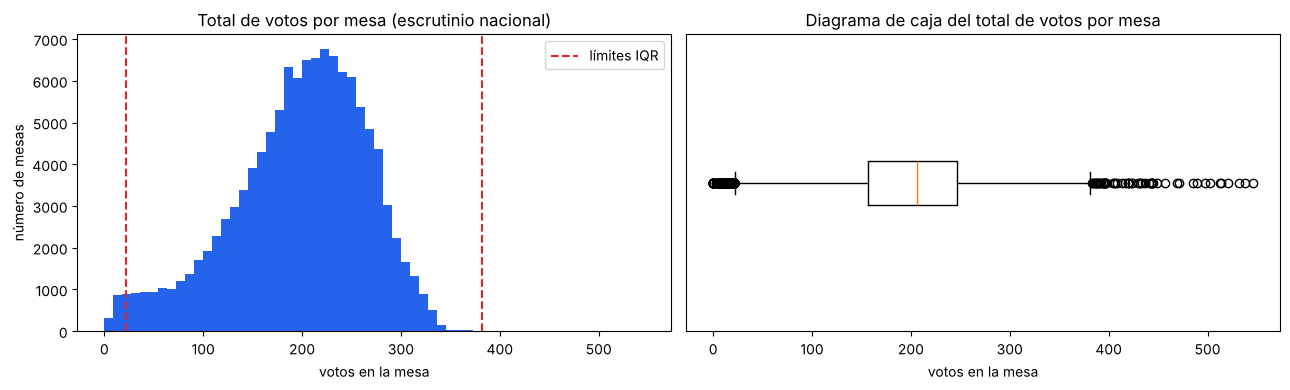

In [ ]:
votos_mesa = escru_nac.groupby(LLAVE_MESA)["votos"].sum().rename("total").reset_index()

Q1 = votos_mesa["total"].quantile(0.25)
Q3 = votos_mesa["total"].quantile(0.75)
IQR = Q3 - Q1
lim_inf, lim_sup = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
print(f"Q1: {Q1:.0f} | mediana: {votos_mesa['total'].median():.0f} | Q3: {Q3:.0f} | IQR: {IQR:.0f}")
print(f"Límite inferior: {lim_inf:.0f} | límite superior: {lim_sup:.0f}")

votos_mesa["atipico"] = np.select([votos_mesa["total"] < lim_inf, votos_mesa["total"] > lim_sup],
                                  ["bajo", "alto"], "normal")
print(votos_mesa["atipico"].value_counts())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(votos_mesa["total"], bins=60, color="#2563EB")
ax[0].axvline(lim_inf, color="#DC2626", linestyle="--", label="límites IQR")
ax[0].axvline(lim_sup, color="#DC2626", linestyle="--")
ax[0].set_xlabel("votos en la mesa")
ax[0].set_ylabel("número de mesas")
ax[0].set_title("Total de votos por mesa (escrutinio nacional)")
ax[0].legend()
ax[1].boxplot(votos_mesa["total"], orientation="horizontal")
ax[1].set_xlabel("votos en la mesa")
ax[1].set_yticks([])
ax[1].set_title("Diagrama de caja del total de votos por mesa")
plt.tight_layout()
plt.show()

*Figura: Distribución del total de votos por mesa con los límites del rango intercuartílico (elaboración propia).*

Se usaron un método estadístico y uno visual sobre el **total de votos por mesa**, que es la medida que resume el resultado de cada acta:

- **Estadístico, rango intercuartílico (IQR).** Se considera atípica una mesa por debajo de Q1 − 1,5·IQR o por encima de Q3 + 1,5·IQR. Con Q1 = 157, Q3 = 247 e IQR = 90, los límites son 22 y 382 votos. Se eligió el IQR porque no supone una distribución normal, y la distribución de los votos por mesa es asimétrica, con una cola larga hacia los valores bajos.
- **Visual: histograma y diagrama de caja.** Muestran que la mayoría de las mesas está entre 100 y 300 votos, con una cola de mesas pequeñas a la izquierda y unos pocos puntos aislados a la derecha.

Resultado: **1 482 atípicos bajos** (menos de 22 votos) y **56 atípicos altos** (más de 382 votos), es decir, el 1,3 % de las 118 350 mesas.

**¿Son errores de medición o representan información válida pero excepcional?**

Para responder se usa la columna `potencial` de novedades, que indica el número **máximo** de votantes que puede tener cada mesa (no cuántos votaron). Casi todas las mesas tienen un potencial de 360, y algunas mesas especiales de 500, 800 o 1 200.

In [ ]:
votos_mesa = votos_mesa.merge(noved[LLAVE_MESA + ["potencial", "excluida"]], on=LLAVE_MESA)
print("Mesas con más votos que su potencial máximo:", (votos_mesa["total"] > votos_mesa["potencial"]).sum())
print("Máximo de votos / potencial:", round((votos_mesa["total"] / votos_mesa["potencial"]).max(), 3))

votos_mesa["n_mesa"] = votos_mesa["mesa"].astype(int)
PUESTO = ["dep", "mun", "zona", "puesto"]
votos_mesa["ultima_mesa"] = votos_mesa["n_mesa"] == votos_mesa.groupby(PUESTO)["n_mesa"].transform("max")

bajos = votos_mesa[votos_mesa["atipico"] == "bajo"]
print(f"\nAtípicos bajos: {len(bajos)}")
print(f"- son la última mesa de su puesto: {bajos['ultima_mesa'].mean() * 100:.1f} % "
      f"(todas las mesas: {votos_mesa['ultima_mesa'].mean() * 100:.1f} %)")
print(f"- mesas excluidas por la comisión (0 votos): {(bajos['excluida'] == 'SI').sum()}")

altos = votos_mesa[votos_mesa["atipico"] == "alto"]
print(f"\nAtípicos altos: {len(altos)}")
print("- potencial máximo de esas mesas:", altos["potencial"].value_counts().to_dict())
print("- potencial máximo de todas las mesas:", votos_mesa["potencial"].value_counts().to_dict())

Mesas con más votos que su potencial máximo: 0
Máximo de votos / potencial: 0.969

Atípicos bajos: 1482
- son la última mesa de su puesto: 87.2 % (todas las mesas: 11.4 %)
- mesas excluidas por la comisión (0 votos): 37

Atípicos altos: 56
- potencial máximo de esas mesas: {800: 54, 500: 2}
- potencial máximo de todas las mesas: {360: 117022, 800: 572, 500: 467, 1200: 289}


Para saber si los atípicos eran errores se aplicó una **regla de validación**: una mesa no puede tener más votos que su potencial máximo (`potencial`, el número máximo de votantes que la ley permite asignarle). **Ninguna mesa supera su potencial**; la que más se acerca llega al 96,9 %. No hay valores imposibles, así que los atípicos no son errores de registro. Cada grupo tiene además una explicación propia:

- **Atípicos bajos (1 482): son en su mayoría la última mesa del puesto.** El 87,2 % de ellos es la mesa con el número más alto de su puesto, frente al 11,4 % del total de mesas. Los votantes se reparten entre las mesas en orden y la última recibe solo los que sobran, por eso tiene pocos votos. Entre ellos están también las 37 mesas excluidas por la comisión, que tienen 0 votos.
- **Atípicos altos (56): son mesas diseñadas para más votantes.** Las 56 tienen un potencial de 800 (54) o 500 (2), cuando casi todas las mesas del país (117 022) tienen un potencial de 360. Su tamaño es atípico frente al total, pero normal frente a su capacidad.

Por lo tanto, los atípicos representan **información válida pero excepcional**: mesas pequeñas o grandes por la forma en que se organiza la votación.

**¿Cuál fue la decisión final sobre cómo tratar los valores atípicos y por qué?**

**Se conservan los 1 538 atípicos sin eliminarlos ni recortarlos**, por tres razones:

1. **No son errores.** Ninguna mesa supera su potencial y cada grupo tiene una explicación en la organización de la votación (última mesa del puesto, mesas con potencial mayor).
2. **Eliminarlos sesgaría el conjunto.** Quitar los atípicos bajos borraría sobre todo las últimas mesas de cada puesto y las 37 mesas excluidas, que además son mesas corregidas. Quitarlos le restaría casos positivos a la variable objetivo.
3. **Lo atípico es parte de lo que el modelo debe aprender.** El objetivo es detectar mesas que cambian en el escrutinio. Recortar o reemplazar valores extremos borraría información que puede estar asociada a esos cambios.

Tampoco se aplicó una transformación en esta etapa. Si en el modelado se usan modelos sensibles a la escala (como la regresión logística), se evaluará estandarizar o aplicar logaritmos. Los modelos basados en árboles no lo necesitan.

### **1.4. Datos Inconsistentes**
---
Frente a inconsistencias en los datos, es importante analizar cómo estas discrepancias podrían afectar la comparabilidad y comprensión de la información.

* ¿Cómo se identificaron las inconsistencias en los datos?
* ¿Las inconsistencias son lo suficientemente significativas como para justificar una estandarización?
* ¿Cómo se pueden homogeneizar unidades y formatos para garantizar coherencia en el análisis?
* ¿Qué estrategias se implementaron para abordar las inconsistencias y asegurar la coherencia?
* ¿Se establecieron reglas de validación específicas para garantizar la consistencia?

#### Escrutinio

**¿Cómo se identificaron las inconsistencias en los datos?**

In [ ]:
# Se vuelven a leer los códigos tal como vienen en los archivos originales (sin normalizar)
esc_crudo = pd.read_csv(ARCH_ESCRUTINIO, sep=";", header=None, usecols=[1, 2, 3, 4, 5, 9],
                        names=["dep", "mun", "zona", "puesto", "mesa", "partido"],
                        dtype=str, encoding="latin-1")
pre_crudo = pd.read_fwf(ARCH_PRECONTEO, widths=ANCHOS_PRE, names=COLS_PRE,
                        dtype=str, encoding="latin-1")
nov_crudo = leer_novedades(ARCH_NOVEDADES).rename(columns={
    "departamentoCodigo": "dep", "municipioCodigo": "mun", "zonaNombre": "zona",
    "puestoCodigo": "puesto", "mesaNumero": "mesa"})

CODIGOS = ["dep", "mun", "zona", "puesto", "mesa", "partido"]
formatos = pd.DataFrame({
    "escrutinio": [sorted(esc_crudo[c].str.len().unique().tolist()) for c in CODIGOS],
    "preconteo":  [sorted(pre_crudo[c].str.len().unique().tolist()) for c in CODIGOS],
    "novedades":  [sorted(nov_crudo[c].str.len().unique().tolist()) if c in nov_crudo else "-" for c in CODIGOS],
}, index=CODIGOS)
print("Número de dígitos de cada código en los archivos originales:")
display(formatos)

print("Primera mesa de cada archivo (zona, mesa):")
print("  escrutinio:", esc_crudo.loc[0, ["zona", "mesa"]].tolist())
print("  preconteo: ", pre_crudo.loc[0, ["zona", "mesa"]].tolist())
print("  novedades: ", nov_crudo.loc[0, ["zona", "mesa"]].tolist())

Número de dígitos de cada código en los archivos originales:


,escrutinio,preconteo,novedades
dep,[2],[2],[2]
mun,[3],[3],[3]
zona,[3],[2],[2]
puesto,[2],[2],[2]
mesa,[6],[6],"[1, 2, 3]"
partido,[4],[5],-


Primera mesa de cada archivo (zona, mesa):
  escrutinio: ['001', '000001']
  preconteo:  ['01', '000001']
  novedades:  ['01', '1']


Las inconsistencias se identificaron comparando el **formato de los códigos** que forman la llave de la mesa en las tres fuentes. Como los códigos se leen como texto, se contó cuántos dígitos tiene cada uno en cada archivo. Se encontraron tres diferencias:

- **Zona:** el escrutinio usa 3 dígitos (`001`); el preconteo y las novedades usan 2 (`01`).
- **Mesa:** el escrutinio y el preconteo usan 6 dígitos con ceros a la izquierda (`000001`); las novedades no usan ceros (`1`, `12`, `123`).
- **Partido:** el escrutinio usa 4 dígitos (`0026`); el preconteo usa 5 (`00026`).

Es decir, la misma mesa aparece escrita de forma distinta en cada fuente: zona `001` y mesa `000001` en el escrutinio, pero zona `01` y mesa `1` en las novedades. Los demás códigos (departamento, municipio y puesto) tienen el mismo formato en todas.

**¿Las inconsistencias son lo suficientemente significativas como para justificar una estandarización?**

In [ ]:
mesas_esc_crudo = esc_crudo[esc_crudo["dep"] != "88"][LLAVE_MESA].drop_duplicates()
cruce_crudo = mesas_esc_crudo.merge(nov_crudo[LLAVE_MESA], on=LLAVE_MESA)

mesas_esc = escru_nac[LLAVE_MESA].drop_duplicates()
cruce_norm = mesas_esc.merge(noved[LLAVE_MESA], on=LLAVE_MESA)

print("Mesas del escrutinio:", len(mesas_esc))
print("Mesas emparejadas con novedades — formatos originales:   ", len(cruce_crudo))
print("Mesas emparejadas con novedades — formatos estandarizados:", len(cruce_norm))

del esc_crudo, pre_crudo, nov_crudo   # liberar memoria

Mesas del escrutinio: 118350
Mesas emparejadas con novedades — formatos originales:    0
Mesas emparejadas con novedades — formatos estandarizados: 118350


Sí, son críticas. Con los formatos originales, **ninguna** de las 118 350 mesas del escrutinio se empareja con las novedades: para pandas, `001` y `01` son textos distintos. Sin estandarizar, no se podrían unir las fuentes ni construir la variable objetivo. Con los formatos estandarizados se emparejan las 118 350 mesas.

**¿Cómo se pueden homogeneizar unidades y formatos para garantizar coherencia en el análisis?**

In [ ]:
print("Dígitos después de estandarizar:")
for c in ["zona", "mesa", "partido"]:
    linea = (f"  {c}: escrutinio {sorted(escru_nac[c].str.len().unique().tolist())}"
             f" | preconteo {sorted(precon[c].str.len().unique().tolist())}")
    if c in noved:
        linea += f" | novedades {sorted(noved[c].str.len().unique().tolist())}"
    print(linea)

print("\nTipos de dato del escrutinio:")
print(escru_nac.dtypes.to_string())

Dígitos después de estandarizar:


  zona: escrutinio [3] | preconteo [3] | novedades [3]


  mesa: escrutinio [6] | preconteo [6] | novedades [6]
  partido: escrutinio [5] | preconteo [5]

Tipos de dato del escrutinio:
comunicado       str
dep              str
mun              str
zona             str
puesto           str
mesa             str
comuna           str
corporacion      str
circ             str
partido          str
candidato        str
votos          int64


**Formatos.** Se tomó como estándar el formato más largo de cada código y se completaron los demás con ceros a la izquierda usando `str.zfill()` (en la celda de carga): zona a 3 dígitos, mesa a 6 y partido a 5. Después de estandarizar, cada código tiene la misma cantidad de dígitos en todas las fuentes.

**Tipos de dato.** Los códigos se mantienen como **texto** y no como números. Si se convirtieran a número, `01` y `1` quedarían iguales, pero se perderían los ceros a la izquierda y códigos como `00026` dejarían de corresponder al catálogo oficial. La única variable numérica es `votos`, que se convierte a entero (`int64`).

**Unidades.** No hubo que homogeneizar unidades: todas las variables numéricas del escrutinio son conteos de votos, en la misma unidad.

**¿Qué estrategias se implementaron para abordar las inconsistencias y asegurar la coherencia?**

In [ ]:
tot_pre = precon[precon["dep"] != "88"].groupby("candidato")["votos"].sum()
tot_esc = escru_nac.groupby("candidato")["votos"].sum()

retiro = pd.DataFrame({"preconteo": tot_pre[["009", "013", "998"]],
                       "escrutinio": tot_esc[["009", "013", "998"]]})
retiro.loc["009 + 013 + 998"] = retiro.sum()
display(retiro)

,preconteo,escrutinio
candidato,,
009,12523,0
013,13018,0
998,47341,68732
009 + 013 + 998,72882,68732


Además de estandarizar los códigos, se encontró una **inconsistencia de contenido entre fuentes**: los candidatos 009 y 013 tienen votos en el preconteo (12 523 y 13 018 en las mesas nacionales), pero 0 en el escrutinio, porque se retiraron y sus votos pasaron a la categoría 998 (votos no marcados). Si las fuentes se comparan sin tener esto en cuenta, casi todas las mesas con votos para esos candidatos parecerían corregidas, aunque el acta no haya cambiado.

La estrategia fue **comparar las tres categorías juntas**. En el preconteo, 009 + 013 + 998 suman 72 882 votos, y en el escrutinio la categoría 998 tiene 68 732. Al construir la variable objetivo, el traslado de 009 y 013 se descuenta mesa por mesa. Así solo cuentan como corrección los cambios del 998 que van **más allá** del traslado, como los 4 150 votos de diferencia que quedan en el total.

En resumen, las estrategias fueron:

1. Estandarizar los códigos con ceros a la izquierda, para que la misma mesa se escriba igual en todas las fuentes.
2. Mantener los códigos como texto y los votos como enteros.
3. Descontar el traslado de los candidatos retirados al comparar las fuentes.
4. Verificar la coherencia con reglas de validación (siguiente pregunta).

**¿Se establecieron reglas de validación específicas para garantizar la consistencia?**

In [ ]:
votos_mesa = (escru_nac.groupby(LLAVE_MESA)["votos"].agg(total="sum", filas="size").reset_index()
              .merge(noved[LLAVE_MESA + ["potencial", "sufragantesSegunE11",
                                         "sufragantesE11SegunE14", "totalVotos"]], on=LLAVE_MESA))

CODIGOS_VALIDOS = set(candidatos["candidato"]) | {"996", "997", "998"}
partido_esc = escru_nac[["candidato", "partido"]].drop_duplicates()
partido_pre = precon[["candidato", "partido"]].drop_duplicates()
puestos = escru_nac[["dep", "mun", "zona", "puesto"]].drop_duplicates()
en_divipol = puestos.merge(divipol[["dep", "mun", "zona", "puesto"]], how="left", indicator=True)

reglas = pd.DataFrame({
    "regla": [
        "Votos no negativos",
        "Cada mesa tiene 16 filas (una por opción)",
        "Código de candidatura existe en el catálogo",
        "Cada candidatura tiene un solo partido, igual en ambas fuentes",
        "El puesto existe en DIVIPOL",
        "Candidatos retirados (009, 013) con 0 votos",
        "Total de la mesa ≤ potencial máximo",
        "Total de la mesa = totalVotos de novedades",
        "Total de la mesa ≤ votantes del E-11",
    ],
    "incumplimientos": [
        (escru_nac["votos"] < 0).sum(),
        (votos_mesa["filas"] != 16).sum(),
        (~escru_nac["candidato"].isin(CODIGOS_VALIDOS)).sum(),
        len(partido_esc.merge(partido_pre, how="outer", indicator=True).query("_merge != 'both'"))
            + partido_esc["candidato"].duplicated().sum(),
        (en_divipol["_merge"] == "left_only").sum(),
        (escru_nac.loc[escru_nac["candidato"].isin(["009", "013"]), "votos"] > 0).sum(),
        (votos_mesa["total"] > votos_mesa["potencial"]).sum(),
        (votos_mesa["total"] != votos_mesa["totalVotos"]).sum(),
        (votos_mesa["total"] > votos_mesa["sufragantesSegunE11"]).sum(),
    ],
})
display(reglas)

print("Mesas donde el escrutinio supera al E-11:")
display(votos_mesa.loc[votos_mesa["total"] > votos_mesa["sufragantesSegunE11"],
                       LLAVE_MESA + ["total", "sufragantesSegunE11", "sufragantesE11SegunE14"]])

,regla,incumplimientos
0,Votos no negativos,0
1,Cada mesa tiene 16 filas (una por opción),0
2,Código de candidatura existe en el catálogo,0
3,"Cada candidatura tiene un solo partido, igual ...",0
4,El puesto existe en DIVIPOL,0
5,"Candidatos retirados (009, 013) con 0 votos",0
6,Total de la mesa ≤ potencial máximo,0
7,Total de la mesa = totalVotos de novedades,0
8,Total de la mesa ≤ votantes del E-11,2


Mesas donde el escrutinio supera al E-11:


,dep,mun,zona,puesto,mesa,total,sufragantesSegunE11,sufragantesE11SegunE14
28042,07,061,000,00,000004,127,0,127
54369,16,001,006,36,000004,295,287,295


Sí. Se definieron nueve reglas que un escrutinio coherente debe cumplir: unas revisan el archivo por dentro (valores, estructura y catálogos) y otras lo comparan con las demás fuentes. **El escrutinio cumple ocho de las nueve reglas sin ninguna excepción**: no hay votos negativos, todas las mesas tienen sus 16 opciones, los códigos y partidos coinciden con el catálogo y con el preconteo, los 13 489 puestos existen en DIVIPOL, los candidatos retirados tienen 0 votos, ninguna mesa supera su potencial y el total coincide con `totalVotos` en todas las mesas.

La única regla con incumplimientos es **"total ≤ votantes del E-11"**, en 2 de 118 350 mesas: el escrutinio tiene más votos que personas registradas en el E-11. En las dos, el valor que no cuadra es el E-11 y no el escrutinio:

- En una mesa el E-11 es **0**, pero el acta E-14 registra 127 votantes y el escrutinio tiene 127 votos.
- En la otra el E-11 es **287**, mientras el E-14 y el escrutinio coinciden en 295.

Como el E-14 confirma los votos del escrutinio, la inconsistencia está en el registro del E-11 del archivo de novedades. Por eso el escrutinio no se modifica, y el tratamiento de esos registros del E-11 se aborda en datos corruptos (1.5).

### **1.5. Datos corruptos**
---
En la detección de datos corruptos, pregunte si hay posibles errores de entrada o problemas de transferencia que podrían haber afectado la integridad de los datos.
* ¿Cómo se determinó la presencia de datos corruptos en el conjunto de datos?
* ¿Qué medidas se tomaron para corregir o eliminar los datos corruptos?
* ¿Hubo casos en los que la corrupción de datos no pudo ser manejada y cómo se justificó esa decisión?

#### Escrutinio

**¿Cómo se determinó la presencia de datos corruptos en el conjunto de datos?**

Se revisaron dos tipos de corrupción: (1) que el archivo se haya dañado o modificado durante la descarga o la transferencia, y (2) que haya líneas mal formadas o con caracteres que no corresponden.

In [ ]:
import hashlib
import re

# 1. Integridad del archivo: huella MD5 publicada por la Registraduría frente a la calculada
texto_hash = buscar_archivo("HASH_ficheros_MMV_4_MMV_9999_ESCRUTINIO.txt").read_text(encoding="utf-16")
md5_oficial = re.search(r"MD5\s*:\s*(\w+)", texto_hash).group(1)

md5 = hashlib.md5()
with open(ARCH_ESCRUTINIO, "rb") as f:
    for bloque in iter(lambda: f.read(1024 * 1024), b""):
        md5.update(bloque)

print("MD5 oficial:  ", md5_oficial)
print("MD5 calculado:", md5.hexdigest())
print("¿Coinciden?", md5_oficial == md5.hexdigest())
print("Tamaño en disco:", os.path.getsize(ARCH_ESCRUTINIO), "bytes")

MD5 oficial:   08ae9a4affd1f0c7fdab6c90e8ea2805
MD5 calculado: 08ae9a4affd1f0c7fdab6c90e8ea2805
¿Coinciden? True
Tamaño en disco: 105425280 bytes


**Integridad del archivo.** La Registraduría publica junto a cada archivo una huella MD5, un código que cambia por completo si se altera un solo byte. La huella calculada sobre el archivo descargado (`08ae9a4affd1f0c7fdab6c90e8ea2805`) es **idéntica a la oficial**, y el tamaño (105 425 280 bytes) coincide con el publicado. Esto garantiza que el archivo no se dañó en la descarga ni se modificó después.

In [ ]:
# 2. Revisión línea por línea del archivo original
from collections import Counter

campos_por_linea = Counter()
lineas_no_numericas = 0
total_lineas = 0
with open(ARCH_ESCRUTINIO, encoding="latin-1") as f:
    for linea in f:
        total_lineas += 1
        partes = linea.rstrip("\r\n").split(";")
        campos_por_linea[len(partes)] += 1
        if not all(p.isdigit() for p in partes[:12]):
            lineas_no_numericas += 1

print("Líneas leídas:", total_lineas, "| filas cargadas en el DataFrame:", len(escru))
print("Campos por línea:", dict(campos_por_linea))
print("Líneas con algún campo no numérico:", lineas_no_numericas)

Líneas leídas: 1952320 | filas cargadas en el DataFrame: 1952320
Campos por línea: {13: 1952320}
Líneas con algún campo no numérico: 14896


**Estructura de las líneas.** Las 1 952 320 líneas tienen exactamente 13 campos (12 datos más un campo final vacío), y todas se cargaron en el DataFrame, sin líneas cortadas ni perdidas. Sin embargo, **14 896 líneas tienen algún campo con caracteres no numéricos**, aunque el escrutinio debería contener solo códigos y votos numéricos. Se investigaron en la siguiente celda.

In [ ]:
alfa = escru[~escru["puesto"].str.isdigit()]
print("Filas con código de puesto alfanumérico:", len(alfa))
print("Mesas:", alfa.groupby(LLAVE_MESA).ngroups,
      "| puestos:", alfa[["dep", "mun", "zona", "puesto"]].drop_duplicates().shape[0])
print("Ejemplos de códigos:", sorted(alfa["puesto"].unique())[:10])
print("Zonas donde aparecen:", alfa["zona"].value_counts().to_dict())

puestos_alfa = alfa[["dep", "mun", "zona", "puesto"]].drop_duplicates().merge(
    divipol[["dep", "mun", "zona", "puesto", "puesto_nombre"]], how="left", indicator=True)
print("Puestos alfanuméricos que existen en DIVIPOL:", (puestos_alfa["_merge"] == "both").sum(),
      "de", len(puestos_alfa))
display(puestos_alfa[["dep", "mun", "zona", "puesto", "puesto_nombre"]].head(3))

Filas con código de puesto alfanumérico: 14896
Mesas: 931 | puestos: 187
Ejemplos de códigos: ['A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'A7', 'A8', 'A9', 'B1']
Zonas donde aparecen: {'099': 10608, '008': 2496, '011': 1792}
Puestos alfanuméricos que existen en DIVIPOL: 187 de 187


,dep,mun,zona,puesto,puesto_nombre
0,01,001,099,A1,IE SAN ANTONIO DE PRADO
1,01,001,099,A2,I.E. MANUEL J. BETANCUR
2,01,001,099,A3,IE MONSEÑOR VICTOR WIEDEMANN


Todos los caracteres no numéricos están en el **código de puesto**, que en 187 puestos (931 mesas) tiene letras: `A1`, `A2`, `B1`, etc. Se ubican sobre todo en la zona 099 (rural). Parecían datos corruptos, pero no lo son: **los 187 códigos existen en el catálogo oficial DIVIPOL**, que les asigna nombres de puestos reales (por ejemplo, `A1` = IE San Antonio de Prado, en Medellín). Es una forma válida de codificar puestos, y el preconteo usa los mismos códigos.

Este hallazgo confirma por qué los códigos se mantienen como **texto**. Si se convirtieran a número, estos 187 puestos producirían errores o se perderían.

**¿Qué medidas se tomaron para corregir o eliminar los datos corruptos?**

In [ ]:
validacion = (escru_nac.groupby(LLAVE_MESA)["votos"].sum().rename("total_esc").reset_index()
              .merge(noved[LLAVE_MESA + ["potencial", "sufragantesSegunE11"]], on=LLAVE_MESA))

validacion["e11_igual_potencial"] = validacion["sufragantesSegunE11"] == validacion["potencial"]
validacion["e11_menor_escrutinio"] = validacion["sufragantesSegunE11"] < validacion["total_esc"]
validacion["e11_sospechoso"] = (validacion["e11_igual_potencial"]
                                | validacion["e11_menor_escrutinio"]).astype(int)

print("E-11 igual al potencial máximo:", validacion["e11_igual_potencial"].sum())
print("E-11 menor que los votos del escrutinio:", validacion["e11_menor_escrutinio"].sum())
print("Mesas marcadas con e11_sospechoso:", validacion["e11_sospechoso"].sum(), "de", len(validacion))

s = validacion[validacion["e11_igual_potencial"]]
print(f"\nMesas con E-11 = potencial: mediana del E-11 {s['sufragantesSegunE11'].median():.0f} | "
      f"mediana de votos del escrutinio {s['total_esc'].median():.0f}")
print(f"Porcentaje de mesas marcadas: {validacion['e11_sospechoso'].mean() * 100:.2f} %")

E-11 igual al potencial máximo: 143
E-11 menor que los votos del escrutinio: 2
Mesas marcadas con e11_sospechoso: 145 de 118350

Mesas con E-11 = potencial: mediana del E-11 360 | mediana de votos del escrutinio 221
Porcentaje de mesas marcadas: 0.12 %


**En el escrutinio no fue necesario corregir ni eliminar nada.** El archivo coincide con la huella oficial, todas sus líneas están completas y los únicos valores que parecían anómalos (los puestos alfanuméricos) son códigos válidos.

Donde sí hay registros corruptos es en el **E-11** del archivo de novedades, que se usa para validar el escrutinio y construir la principal variable del modelo:

- **143 mesas con el E-11 igual al potencial máximo.** El E-11 dice que firmaron 360 personas (el máximo de la mesa), pero el escrutinio tiene una mediana de 221 votos. Lo más probable es que se haya registrado el potencial en lugar del número real de votantes.
- **2 mesas con el E-11 menor que los votos del escrutinio** (las encontradas en la 1.4): una con E-11 = 0 y otra con 287 votantes frente a 295 votos.

**Medida tomada: marcar, no eliminar ni corregir.** Se creó la bandera `e11_sospechoso`, que vale 1 en estas **145 mesas**. Las mesas se conservan, porque su escrutinio es válido y algunas pueden ser mesas corregidas. Al construir las variables del modelo, la diferencia entre el preconteo y el E-11 de estas mesas se dejará como faltante, para que el modelo no tome un error de registro como señal de corrección.

La bandera se guarda en la tabla `validacion` (una fila por mesa) y se incorpora al conjunto de modelado en la selección de datos (1.6).

**¿Hubo casos en los que la corrupción de datos no pudo ser manejada y cómo se justificó esa decisión?**

Sí: el **valor real del E-11** de las 145 mesas marcadas no se puede recuperar. Para conocerlo habría que consultar el formulario físico, que no forma parte de los datos publicados. Estimarlo con el E-14 o con los votos del escrutinio no es correcto, porque el modelo justamente compara esas fuentes. Rellenar el E-11 con una de ellas haría que coincidieran de forma artificial.

Por eso se decidió no corregirlo y solo marcarlo. La bandera deja constancia del problema, y estas mesas son el 0,12 % del conjunto (145 de 118 350), así que su efecto en el modelo es pequeño.

También hay una limitación general: la huella MD5 garantiza que el archivo es el que publicó la Registraduría, pero no que lo publicado coincida con las actas físicas. Esa verificación está fuera del alcance de este trabajo.

### **1.6. Selección de datos**
---
En la selección de datos, reflexione sobre las variables que son realmente relevantes para sus objetivos de análisis.
* ¿Qué criterios se utilizaron para seleccionar los datos relevantes para el análisis?
* ¿Se aplicaron técnicas de muestreo o filtrado para reducir el tamaño del conjunto de datos?
* ¿Cómo se justificó la inclusión o exclusión de ciertas variables en la selección de datos?

#### Escrutinio

**¿Qué criterios se utilizaron para seleccionar los datos relevantes para el análisis?**

In [ ]:
print("Valores distintos por columna (escrutinio nacional):")
print(escru_nac.nunique().to_string())

pares = escru_nac[["candidato", "partido"]].drop_duplicates()
print("\nCandidaturas:", escru_nac["candidato"].nunique(),
      "| combinaciones candidatura-partido:", len(pares))

Valores distintos por columna (escrutinio nacional):


comunicado       1
dep             33
mun            263
zona            42
puesto         208
mesa           228
comuna           1
corporacion      1
circ             1
partido         14
candidato       16
votos          301



Candidaturas: 16 | combinaciones candidatura-partido: 16


El criterio principal fue el **objetivo del proyecto**: predecir si una mesa será corregida en el escrutinio usando información disponible **antes** del escrutinio. Por eso el escrutinio cumple un solo papel en el conjunto de modelado: **aportar la variable objetivo**. Sus votos se usan para saber si la mesa cambió, pero no pueden ser variables de entrada, porque son justamente el resultado que se quiere anticipar.

Con ese criterio se revisaron las 12 columnas del escrutinio:

- **Se conservan** las cinco columnas de la llave (`dep`, `mun`, `zona`, `puesto`, `mesa`), necesarias para unir el escrutinio con el preconteo y las novedades, y `candidato` y `votos`, necesarias para construir la variable objetivo.
- **Se excluyen** `comunicado`, `comuna`, `corporacion` y `circ`, porque tienen **un solo valor** en todo el archivo: no aportan información.
- **Se excluye** `partido`, porque es **redundante** con `candidato`: cada una de las 16 candidaturas tiene un único partido (16 combinaciones para 16 candidaturas). Tiene 14 valores y no 16 porque blanco, nulo y no marcado comparten el código `00000`.

In [ ]:
pre_nac = precon[precon["dep"] != "88"]

# Una fila por mesa y una columna por opción, en cada fuente
esc_ancho = escru_nac.pivot_table(index=LLAVE_MESA, columns="candidato", values="votos",
                                  aggfunc="sum", fill_value=0)
pre_ancho = (pre_nac.pivot_table(index=LLAVE_MESA, columns="candidato", values="votos",
                                 aggfunc="sum", fill_value=0)
                    .reindex(index=esc_ancho.index, columns=esc_ancho.columns, fill_value=0))

# Cambio de cada opción entre preconteo y escrutinio, descontando el retiro de 009 y 013
dif = esc_ancho - pre_ancho
traslado = pre_ancho["009"] + pre_ancho["013"]
ACTIVOS = [c for c in esc_ancho.columns if c not in ("009", "013", "996", "997", "998")]
cambio_998 = dif["998"] - traslado

objetivo = pd.DataFrame(index=esc_ancho.index)
objetivo["magnitud"] = dif[ACTIVOS + ["996", "997"]].abs().sum(axis=1) + cambio_998.abs()
objetivo["y_corregida"] = (objetivo["magnitud"] > 0).astype(int)
objetivo = objetivo.reset_index()

n1 = objetivo["y_corregida"].sum()
print("Mesas:", len(objetivo))
print(f"Mesas corregidas (y = 1): {n1} ({n1 / len(objetivo) * 100:.2f} %)")
print(f"Mesas sin corrección (y = 0): {len(objetivo) - n1}")
print(f"Relación: {(len(objetivo) - n1) / n1:.1f} mesas sin corrección por cada corregida")

Mesas: 118350
Mesas corregidas (y = 1): 5998 (5.07 %)
Mesas sin corrección (y = 0): 112352
Relación: 18.7 mesas sin corrección por cada corregida


Con las columnas seleccionadas se construyó la **variable objetivo** `y_corregida`, que vale 1 si la mesa tuvo algún cambio entre el preconteo y el escrutinio que **no** se explica por el retiro de los candidatos 009 y 013 (ver 1.4): un cambio en una candidatura activa, en el voto en blanco (996), en el nulo (997) o en el 998 más allá del traslado. También se calculó `magnitud`, el número de votos que cambiaron, como variable complementaria para el análisis; no se usa como entrada del modelo.

De las 118 350 mesas nacionales, **5 998 fueron corregidas (5,07 %)**, unas 18,7 mesas sin corrección por cada mesa corregida. Este desbalance se tendrá en cuenta en el modelado (métricas como precisión, sensibilidad o PR-AUC en lugar de la exactitud).

**¿Se aplicaron técnicas de muestreo o filtrado para reducir el tamaño del conjunto de datos?**

In [ ]:
mb_largo = escru_nac.memory_usage(deep=True).sum() / 1024**2
mb_ancho = objetivo.memory_usage(deep=True).sum() / 1024**2
print(f"Escrutinio en formato largo: {len(escru_nac):>9,} filas | {mb_largo:,.0f} MB")
print(f"Una fila por mesa:           {len(objetivo):>9,} filas | {mb_ancho:,.0f} MB")
print("\nMesas corregidas disponibles para entrenar:", objetivo["y_corregida"].sum())

Escrutinio en formato largo: 1,893,600 filas | 1,049 MB
Una fila por mesa:             118,350 filas | 31 MB

Mesas corregidas disponibles para entrenar: 5998


**No se aplicó muestreo.** Las 118 350 mesas se pueden procesar completas sin problema, y un muestreo reduciría las mesas corregidas disponibles para entrenar, que ya son pocas (5 998). Las técnicas para manejar el desbalance, como pesos de clase o submuestreo de la clase mayoritaria, se evaluarán en el modelado, solo sobre el conjunto de entrenamiento.

**Sí se aplicaron dos filtros:**

1. **Exclusión de los consulados** (ver 1.1), porque no tienen datos del formulario en el archivo de novedades.
2. **Cambio de formato largo a una fila por mesa.** La unidad de análisis del proyecto es la mesa, así que el escrutinio pasó de 1 893 600 filas (una por mesa y candidatura) a 118 350 filas (una por mesa). Esto reduce el tamaño en memoria de unos 1 049 MB a 31 MB, sin perder información para el objetivo.

**¿Cómo se justificó la inclusión o exclusión de ciertas variables en la selección de datos?**

In [ ]:
fuga = objetivo.merge(noved[LLAVE_MESA + ["enTerminos", "estadoSobre", "recontadaComision", "excluida"]],
                      on=LLAVE_MESA, validate="1:1")

print(f"Promedio general de mesas corregidas: {fuga['y_corregida'].mean() * 100:.1f} %\n")
for col, valor in {"enTerminos": "NO", "estadoSobre": "MAL",
                   "recontadaComision": "SI", "excluida": "SI"}.items():
    marcadas = fuga[col] == valor
    print(f"{col} = {valor}: {marcadas.sum():>4} mesas | % corregidas: "
          f"{fuga.loc[marcadas, 'y_corregida'].mean() * 100:.1f}")

Promedio general de mesas corregidas: 5.1 %

enTerminos = NO:   12 mesas | % corregidas: 50.0
estadoSobre = MAL:  334 mesas | % corregidas: 5.7
recontadaComision = SI:  558 mesas | % corregidas: 89.2
excluida = SI:   37 mesas | % corregidas: 100.0


La exclusión de variables se justificó con el criterio de **fuga de información**: una variable que se registra durante o después del escrutinio no estará disponible al momento de hacer la predicción. Si se incluyera, el modelo acertaría por una razón que no existe en la práctica. Por eso se excluyen como variables de entrada:

- **Los votos del escrutinio**, por candidatura y en total: son el resultado que se quiere anticipar.
- **`totalVotos`** de novedades: es igual al total del escrutinio en el 100 % de las mesas (ver 1.4).
- **`recontadaComision`** y **`excluida`**: son decisiones de la comisión escrutadora y forman parte del mecanismo de la corrección. El 89,2 % de las mesas recontadas por la comisión y el 100 % de las excluidas fueron corregidas.
- **`estadoSobre`** y **`enTerminos`**: se registran cuando la comisión recibe los sobres, es decir, durante el escrutinio. Su relación con la corrección es más débil (5,7 % y 50 %, este último con solo 12 mesas), pero se excluyen por el mismo criterio de momento de registro.

| Variable | ¿Se incluye? | Razón |
|---|---|---|
| Llave de la mesa (`dep`, `mun`, `zona`, `puesto`, `mesa`) | Sí | Necesaria para unir las fuentes |
| `y_corregida` | Sí, como **objetivo** | Variable a predecir |
| `magnitud` | Sí, como complementaria | Análisis del tamaño de las correcciones; no es entrada |
| `e11_sospechoso` | Sí | Bandera de calidad del E-11 (ver 1.5) |
| `comunicado`, `comuna`, `corporacion`, `circ` | No | Un solo valor en todo el archivo |
| `partido` | No | Redundante con `candidato` |
| Votos del escrutinio, `totalVotos` | No | Fuga: son el resultado del escrutinio |
| `recontadaComision`, `excluida`, `estadoSobre`, `enTerminos` | No | Fuga: se registran durante el escrutinio |

In [ ]:
tabla_escrutinio = objetivo.merge(validacion[LLAVE_MESA + ["e11_sospechoso"]],
                                  on=LLAVE_MESA, validate="1:1")
assert len(tabla_escrutinio) == 118350 and not tabla_escrutinio.duplicated(LLAVE_MESA).any()

print("Forma:", tabla_escrutinio.shape)
print("Columnas:", list(tabla_escrutinio.columns))
print("Nulos:", tabla_escrutinio.isnull().sum().sum())
display(tabla_escrutinio.head())

SALIDA = Path("../../data/processed")
SALIDA.mkdir(parents=True, exist_ok=True)
tabla_escrutinio.to_csv(SALIDA / "objetivo_escrutinio.csv", index=False)
print("Guardado en:", (SALIDA / "objetivo_escrutinio.csv").resolve())

Forma: (118350, 8)
Columnas: ['dep', 'mun', 'zona', 'puesto', 'mesa', 'magnitud', 'y_corregida', 'e11_sospechoso']
Nulos: 0


,dep,mun,zona,puesto,mesa,magnitud,y_corregida,e11_sospechoso
0,01,001,001,01,000001,0,0,0
1,01,001,001,01,000002,0,0,0
2,01,001,001,01,000003,0,0,0
3,01,001,001,01,000004,0,0,0
4,01,001,001,01,000005,0,0,0


Guardado en: /home/claude/repo_sim/data/processed/objetivo_escrutinio.csv


La selección del escrutinio queda en la tabla `tabla_escrutinio`, con **118 350 mesas y 8 columnas**: la llave de la mesa, `magnitud`, `y_corregida` y `e11_sospechoso`. No tiene nulos ni mesas repetidas, y se guardó en `data/processed/objetivo_escrutinio.csv`.

Esta tabla se une por la llave de la mesa con las variables del preconteo y de las novedades, disponibles antes del escrutinio, para formar el conjunto de modelado. En esa unión, la diferencia entre el preconteo y el E-11 de las 145 mesas con `e11_sospechoso = 1` se dejará como faltante (ver 1.5). Para leer el archivo sin perder los ceros a la izquierda de los códigos, se debe usar `pd.read_csv(..., dtype={"dep": str, "mun": str, "zona": str, "puesto": str, "mesa": str})`.

## **Créditos**
---

* **Profesor:** [Fabio Augusto Gonzalez](https://dis.unal.edu.co/~fgonza/)
* **Asistente docente :**
  * [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Diseño de imágenes:**
    - [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Coordinador de virtualización:**
    - [Edder Hernández Forero](https://www.linkedin.com/in/edder-hernandez-forero-28aa8b207/).

**Universidad Nacional de Colombia** - *Facultad de Ingeniería*